## Install library

We install pytrends to fetch Google search data and openpyxl to save results as Excel.

In [1]:
!pip install pytrends openpyxl

## Connect Drive and set the save location

We connect Google Drive so downloaded data is saved and we don’t have to fetch it again.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
save_dir = '/content/drive/MyDrive/deepfake_project'
os.makedirs(save_dir, exist_ok=True)
data_file = f'{save_dir}/trend_data.csv'

Mounted at /content/drive


## Download search data for 100 cities

We download 5 years of weekly Google search interest for 100 Indian destinations, in groups of 5 with pauses and retries to avoid being blocked, save as we go, and drop cities with too little data.

In [3]:
import time
import pandas as pd
from pytrends.request import TrendReq     # unofficial api for google trends search

pytrends = TrendReq(hl='en-US', tz=330)   # initializing api connection setting language and timezone

# Ordered by popularity, so each group of 5 has similar search volume
lists = {
    'popular': ['Goa', 'Manali', 'Shimla', 'Mussoorie', 'Nainital', 'Darjeeling', 'Munnar', 'Ooty',
                'Coorg', 'Kodaikanal', 'Rishikesh', 'Leh', 'Srinagar', 'Jaipur', 'Udaipur', 'Jaisalmer',
                'Jodhpur', 'Agra', 'Varanasi', 'Amritsar', 'Pondicherry', 'Port Blair', 'Alleppey',
                'Mahabaleshwar', 'Lonavala', 'Gangtok', 'Mysore', 'Kochi', 'Hampi', 'Mount Abu',
                'Dharamshala', 'Haridwar', 'Pushkar', 'Gulmarg', 'Kasol', 'Auli'],
    'mid': ['McLeod Ganj', 'Dalhousie', 'Kufri', 'Spiti Valley', 'Tawang', 'Ziro Valley', 'Shillong',
            'Cherrapunji', 'Gokarna', 'Varkala', 'Kovalam', 'Wayanad', 'Thekkady', 'Chikmagalur',
            'Yercaud', 'Coonoor', 'Khajuraho', 'Rann of Kutch', 'Bikaner', 'Chittorgarh', 'Ranthambore',
            'Jim Corbett', 'Kaziranga', 'Pelling', 'Lachung', 'Majuli', 'Alibaug', 'Matheran',
            'Panchgani', 'Mahabalipuram', 'Madurai', 'Rameswaram'],
    'offbeat': ['Chopta', 'Tirthan Valley', 'Mukteshwar', 'Lansdowne', 'Kanatal', 'Binsar', 'Almora',
                'Ranikhet', 'Chitkul', 'Kinnaur', 'Naldehra', 'Jibhi', 'Bir Billing', 'Sangla',
                'Dzukou Valley', 'Mawlynnong', 'Dawki', 'Sandakphu', 'Kalimpong', 'Lavasa',
                'Gurez Valley', 'Pangong Lake', 'Nubra Valley', 'Zanskar', 'Munsiyari', 'Auroville',
                'Dhanushkodi', 'Kumbhalgarh', 'Orchha', 'Mandu', 'Bhimtal', 'Gandikota']
}
tier = {}
for t, cities in lists.items():
    for city in cities:
        tier[city] = t
all_cities = list(tier)

def fetch(cities):
    """5 years of weekly search interest for up to 5 cities, with retries."""
    for attempt in range(1, 6):
        try:
            pytrends.build_payload(cities, timeframe='today 5-y', geo='IN')
            return pytrends.interest_over_time().drop(columns=['isPartial'], errors='ignore')
        except Exception:
            print(f"Blocked, waiting {60 * attempt}s (attempt {attempt}/5)...")
            time.sleep(60 * attempt)
    return None


series = {}
if os.path.exists(data_file):
    series = dict(pd.read_csv(data_file, index_col=0, parse_dates=True).items())
    print("Loaded", len(series), "cities from Drive")

for i in range(0, len(all_cities), 5):          # batch processing
    batch = all_cities[i:i + 5]
    if all(c in series for c in batch):
        continue
    data = fetch(batch)
    if data is None:
        print("Batch failed, re-run this cell to continue from here.")
        break
    series.update({c: data[c] for c in batch if c in data.columns})
    pd.DataFrame(series).to_csv(data_file)          # save progress after every batch
    print(f"{len(series)}/{len(all_cities)} cities done")
    time.sleep(30)

trend_df = pd.DataFrame(series)

# Keep only cities with enough real data
reliable = [c for c in trend_df if (trend_df[c] > 0).mean() >= 0.5]
print("Usable cities:", len(reliable))
print("Dropped:", [c for c in trend_df if c not in reliable])

Loaded 100 cities from Drive
Usable cities: 99
Dropped: ['Ziro Valley']


## Function Logic

We turn each city’s weekly data into a seasonal index, which is how busy each month is compared with that city’s own average. Feature 1 suggests places for a month, and Feature 2 judges one city in one month.


In [4]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


def parse_month(text):
    text = text.strip().lower()
    if text.isdigit() and 1 <= int(text) <= 12:
        return int(text)
    for i, name in enumerate(month_names, 1):
        if text.startswith(name.lower()):
            return i
    raise ValueError("Enter a valid month, like October or 10.")


def month_profile(s):
    """Typical interest per month as an index."""
    monthly = s.groupby(s.index.month).median()
    return monthly / monthly.mean()


# Seasonal index for every city, computed once
month_matrix = pd.DataFrame({c: month_profile(trend_df[c]) for c in reliable}).T
month_matrix.columns = month_names
month_matrix['type'] = month_matrix.index.map(tier)
lookup = {c.lower(): c for c in month_matrix.index}      # case-insensitive city names


def recommend(month_text, top_n=4):
    m = month_names[parse_month(month_text) - 1]
    groups = {'Well-known': month_matrix['type'] != 'offbeat',
              'Offbeat': month_matrix['type'] == 'offbeat'}
    print(f"\nBest places to visit in {m}:")
    for label, mask in groups.items():
        print(f"\n{label} picks:")
        print(month_matrix[mask][m].nlargest(top_n // 2).round(2).to_string())


def check_city_month(city, month_text):
    m = month_names[parse_month(month_text) - 1]
    city = lookup.get(city.strip().lower(), city.strip())

    if city in month_matrix.index:
        prof = month_matrix.loc[city, month_names].astype(float)
    else:                                                # a city outside the pool
        data = fetch([city])
        if data is None or data.empty or data[city].mean() == 0:
            print(f"{city}: not enough search data to judge.")
            return
        prof = month_profile(data[city]).set_axis(month_names)

    rank = int(prof.rank(ascending=False, method='min')[m])   # 1 = best month
    verdict = "GOOD" if rank <= 3 else "AVERAGE" if rank <= 7 else "NOT the best"
    print(f"\n{city} in {m}: seasonal index {prof[m]:.2f} (1.0 = average, above = busier)")
    print(f"Rank: {rank}/12 -> {verdict} time to visit")
    print("Best months:", ", ".join(prof.nlargest(3).index))

## Testing Functions

We test with cases where we already know the answer. The results match real travel seasons, which shows the method works.

In [5]:
for m in ['January', 'May', 'July', 'October']:
    recommend(m)

for city, month in [('Manali', 'June'), ('Manali', 'September'), ('Goa', 'December'), ('Goa', 'July'),
                    ('Leh', 'July'), ('Leh', 'January'), ('Auli', 'January'), ('Gokarna', 'March')]:
    check_city_month(city, month)


Best places to visit in Jan:

Well-known picks:
Kufri    1.83
Auli     1.43

Offbeat picks:
Gandikota      1.36
Dhanushkodi    1.13

Best places to visit in May:

Well-known picks:
Spiti Valley    1.66
Mussoorie       1.62

Offbeat picks:
Tirthan Valley    2.29
Nubra Valley      1.99

Best places to visit in Jul:

Well-known picks:
Cherrapunji    1.60
Matheran       1.52

Offbeat picks:
Gurez Valley    1.57
Lavasa          1.53

Best places to visit in Oct:

Well-known picks:
Rann of Kutch    1.36
Hampi            1.16

Offbeat picks:
Sandakphu    1.23
Gandikota    1.22

Manali in Jun: seasonal index 1.32 (1.0 = average, above = busier)
Rank: 3/12 -> GOOD time to visit
Best months: Dec, May, Jun

Manali in Sep: seasonal index 0.66 (1.0 = average, above = busier)
Rank: 10/12 -> NOT the best time to visit
Best months: Dec, May, Jun

Goa in Dec: seasonal index 1.16 (1.0 = average, above = busier)
Rank: 1/12 -> GOOD time to visit
Best months: Dec, Nov, Jan

Goa in Jul: seasonal index 0.87

In [8]:
!pip install -q prophet

In [9]:
import numpy as np, warnings, logging
warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('prophet').setLevel(logging.ERROR)

# Weekly -> monthly average interest (the current month is incomplete, so it is dropped)
monthly = trend_df[reliable].resample('MS').mean().iloc[:-1]
print(monthly.shape, "| from", monthly.index[0].date(), "to", monthly.index[-1].date())

(60, 99) | from 2021-10-01 to 2026-09-01


In [10]:
from prophet import Prophet
from statsmodels.tsa.statespace.sarimax import SARIMAX

def forecast_prophet(series, steps):
    d = pd.DataFrame({'ds': series.index, 'y': series.values})
    m = Prophet(yearly_seasonality=5, weekly_seasonality=False, daily_seasonality=False)
    m.fit(d)
    fc = m.predict(m.make_future_dataframe(periods=steps, freq='MS'))
    return m, fc, fc['yhat'].values[-steps:]

def forecast_sarima(series, steps):
    fit = SARIMAX(series.values, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12),
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return fit.forecast(steps)

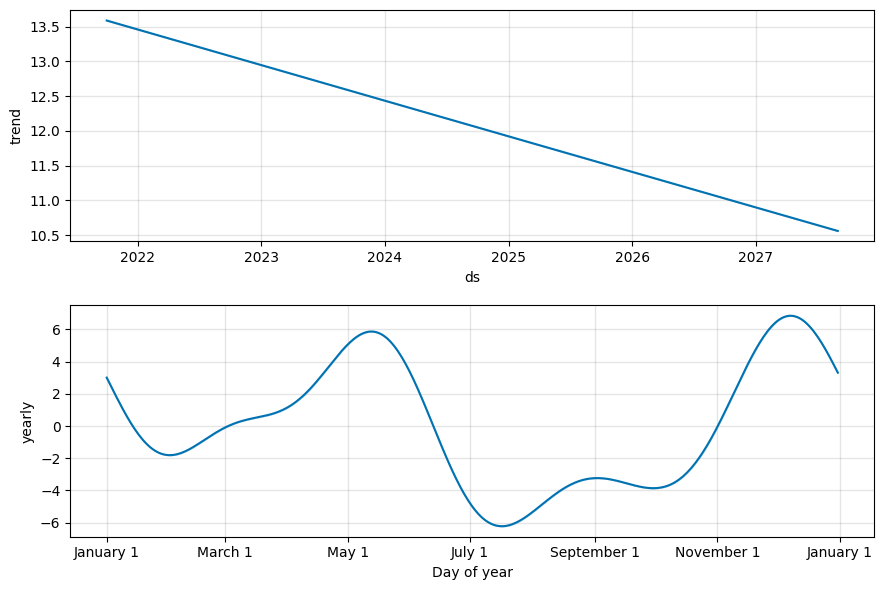

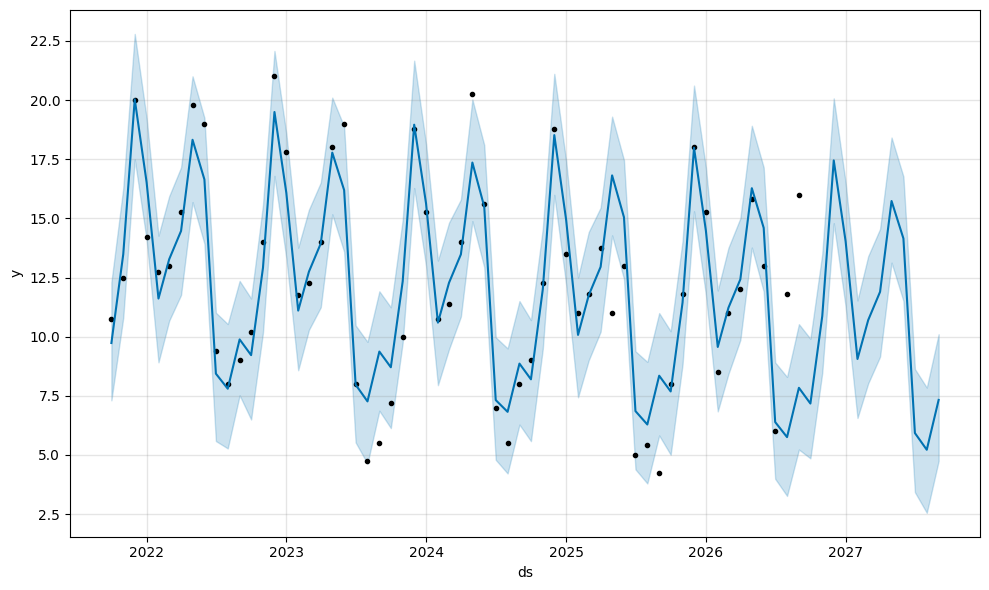

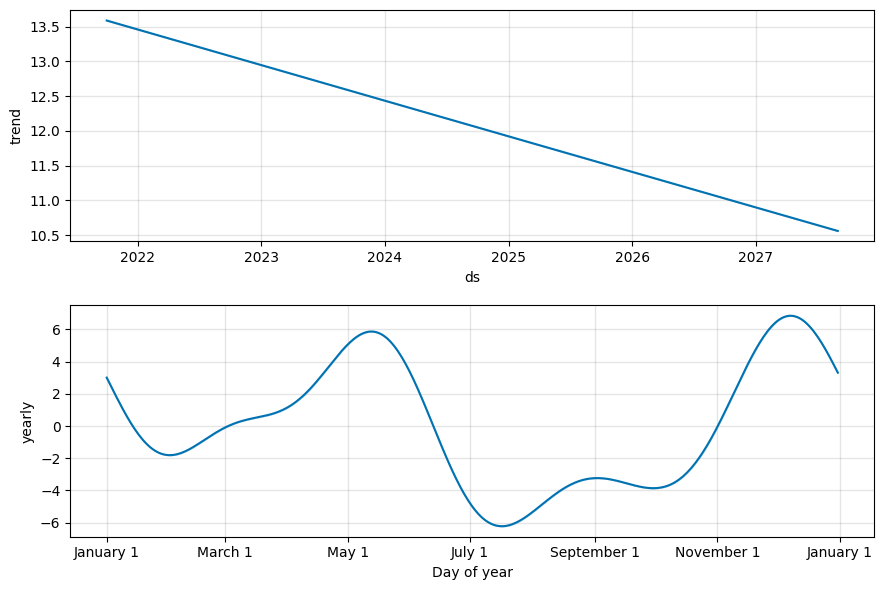

In [11]:
m, fc, _ = forecast_prophet(monthly['Manali'], 12)
m.plot(fc)
m.plot_components(fc)

In [12]:
def nmae_of(actual, pred, scale):
    return np.mean(np.abs(actual - np.clip(pred, 0, None))) / scale

def backtest(city):
    s = monthly[city]
    train, test = s.iloc[:-12], s.iloc[-12:]
    scale = train.mean()
    if scale <= 0:
        return None
    cal = train.groupby(train.index.month).median()
    preds = {'Seasonal naive': train.values[-12:],                       # same as last year
             'Seasonal average': np.array([cal[m] for m in test.index.month])}   # your current method
    try:
        preds['SARIMA'] = np.asarray(forecast_sarima(train, 12))
    except Exception:
        preds['SARIMA'] = preds['Seasonal naive']
    try:
        preds['Prophet'] = forecast_prophet(train, 12)[2]
    except Exception:
        preds['Prophet'] = preds['Seasonal naive']
    row = {'city': city}
    for name, p in preds.items():
        row[name] = nmae_of(test.values, np.asarray(p, float), scale)
    return row

rows = []
for i, city in enumerate(monthly.columns, 1):
    r = backtest(city)
    if r:
        rows.append(r)
    if i % 20 == 0:
        print(f"{i}/{len(monthly.columns)} cities done")

res = pd.DataFrame(rows).set_index('city')
summary = pd.DataFrame({'mean error': res.mean(), 'median error': res.median(),
                        'cities won': res.idxmin(axis=1).value_counts()}).fillna(0)
print(summary.sort_values('mean error').round(3))
res.to_csv(f'{save_dir}/forecast_backtest.csv')

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for v

20/99 cities done


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for v

40/99 cities done


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for v

60/99 cities done


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for v

80/99 cities done


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for v

                  mean error  median error  cities won
Seasonal naive         0.187         0.123          33
Seasonal average       0.206         0.159          32
Prophet                0.207         0.154          16
SARIMA                 0.232         0.168          18


In [13]:
import warnings
warnings.simplefilter('ignore')

def backtest2(city):
    s = monthly[city]
    train, test = s.iloc[:-12], s.iloc[-12:]
    scale = train.mean()
    if scale <= 0:
        return None
    naive = np.asarray(train.values[-12:], float)
    cal = train.groupby(train.index.month).median()
    avg = np.array([cal[m] for m in test.index.month], float)
    try:
        prophet = np.asarray(forecast_prophet(train, 12)[2], float)
    except Exception:
        prophet = naive
    preds = {'Seasonal naive': naive, 'Seasonal average': avg, 'Prophet': prophet,
             'Prophet + seasonal naive': (prophet + naive) / 2,
             'Prophet + seasonal average': (prophet + avg) / 2}
    row = {'city': city}
    for name, p in preds.items():
        row[name] = nmae_of(test.values, p, scale)
    return row

rows2 = [r for r in (backtest2(c) for c in monthly.columns) if r]
res2 = pd.DataFrame(rows2).set_index('city')
res2['SARIMA'] = res['SARIMA']
summary2 = pd.DataFrame({'mean error': res2.mean(), 'median error': res2.median(),
                         'cities won': res2.idxmin(axis=1).value_counts()}).fillna(0)
print(summary2.sort_values('mean error').round(3))
res2.to_csv(f'{save_dir}/forecast_backtest_v2.csv')

                            mean error  median error  cities won
Prophet + seasonal average       0.179         0.128          14
Prophet + seasonal naive         0.184         0.123          14
Seasonal naive                   0.187         0.123          21
Seasonal average                 0.206         0.159          25
Prophet                          0.207         0.154          10
SARIMA                           0.232         0.168          15


In [14]:
future_months = pd.date_range(monthly.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq='MS')
print("Forecasting", future_months[0].strftime('%b %Y'), "to", future_months[-1].strftime('%b %Y'))

forecasts, growth_pct = {}, {}
for i, city in enumerate(monthly.columns, 1):
    s = monthly[city]
    cal = s.groupby(s.index.month).median()
    seasonal_avg = np.array([cal[d.month] for d in future_months], float)
    try:
        _, fc, prophet_pred = forecast_prophet(s, 12)
        base = max(abs(fc['trend'].iloc[-13]), 1.0)
        growth_pct[city] = (fc['trend'].iloc[-1] - fc['trend'].iloc[-13]) / base * 100
        pred = (np.asarray(prophet_pred, float) + seasonal_avg) / 2       # the final model
    except Exception:
        pred, growth_pct[city] = seasonal_avg, 0.0
    forecasts[city] = np.clip(pred, 0, None)
    if i % 25 == 0:
        print(f"{i}/{len(monthly.columns)} cities done")

forecast_df = pd.DataFrame(forecasts, index=future_months).T
forecast_df.columns = [month_names[d.month - 1] for d in future_months]
forecast_df = forecast_df[month_names]                                  # Jan to Dec order

# Forecast index: 1.0 = that city's average forecast month
fmatrix = forecast_df.div(forecast_df.mean(axis=1).replace(0, np.nan), axis=0)
fmatrix = fmatrix.dropna(subset=month_names)
fmatrix['growth_pct'] = pd.Series(growth_pct)
fmatrix['trend'] = np.where(fmatrix['growth_pct'] > 10, 'Rising',
                   np.where(fmatrix['growth_pct'] < -10, 'Falling', 'Stable'))
fmatrix['type'] = fmatrix.index.map(tier)
lookup = {c.lower(): c for c in fmatrix.index}
print(fmatrix['trend'].value_counts())

Forecasting Oct 2026 to Sep 2027
25/99 cities done
50/99 cities done
75/99 cities done
trend
Stable     71
Falling    20
Rising      8
Name: count, dtype: int64


In [17]:
def recommend(month_text, top_n=4):
    m = month_names[parse_month(month_text) - 1]
    print(f"\nBest places to visit in {m}:")
    groups = {'Well-known': fmatrix['type'] != 'offbeat', 'Offbeat': fmatrix['type'] == 'offbeat'}
    for label, mask in groups.items():
        top = fmatrix[mask].sort_values(m, ascending=False).head(top_n // 2)
        print(f"\n{label} picks:")
        print(top[[m, 'trend', 'growth_pct']].rename(columns={m: 'forecast_index'}).round(2).to_string())

def check_city_month(city, month_text):
    m = month_names[parse_month(month_text) - 1]
    key = lookup.get(city.strip().lower())
    if key is None:
        print(f"'{city}' is not in the dataset of {len(fmatrix)} destinations.")
        return
    row = fmatrix.loc[key, month_names].astype(float)
    rank = int(row.rank(ascending=False)[m])
    verdict = ('GOOD time to visit' if rank <= 3 else
               'AVERAGE time to visit' if rank <= 7 else 'NOT the best time to visit')
    best = row.sort_values(ascending=False).head(3).index.tolist()
    print(f"\n{key} in {m}: forecast index {row[m]:.2f} (1.0 = average month, above = busier)")
    print(f"Rank: {rank}/12 -> {verdict}")
    print(f"Best months: {', '.join(best)}")
    print(f"Overall trend: {fmatrix.loc[key, 'trend']} ({fmatrix.loc[key, 'growth_pct']:+.0f}% over the next 12 months)")

# quick test
recommend('June')
recommend('December')
for city, month in [('Manali', 'June'), ('Goa', 'December'), ('Goa', 'July'), ('Leh', 'July')]:
    check_city_month(city, month)


Best places to visit in Jun:

Well-known picks:
           forecast_index   trend  growth_pct
Matheran             1.71  Stable       -2.07
Mussoorie            1.67  Stable       -2.27

Offbeat picks:
                forecast_index    trend  growth_pct
Nubra Valley              2.25  Falling      -18.54
Tirthan Valley            2.08   Stable       -2.61

Best places to visit in Dec:

Well-known picks:
               forecast_index   trend  growth_pct
Auli                     2.33  Stable       -5.40
Rann of Kutch            2.15  Stable       -3.84

Offbeat picks:
           forecast_index   trend  growth_pct
Sandakphu            1.69  Stable       -8.57
Gandikota            1.49  Stable       -0.80

Manali in Jun: forecast index 1.29 (1.0 = average month, above = busier)
Rank: 3/12 -> GOOD time to visit
Best months: Dec, May, Jun
Overall trend: Stable (-5% over the next 12 months)

Goa in Dec: forecast index 1.17 (1.0 = average month, above = busier)
Rank: 1/12 -> GOOD time to visi

## User Interaction

A simple menu so anyone can use the recommender without touching the code.

In [19]:
def show_forecast(city):
    key = lookup.get(city.strip().lower())
    if key is None:
        print(f"'{city}' is not in the dataset of {len(fmatrix)} destinations.")
        return
    print(f"\nForecast of search interest for {key} (relative scale), by month:")
    print(forecast_df.loc[key].round(1).to_string())
    print(f"Overall trend: {fmatrix.loc[key, 'trend']} ({fmatrix.loc[key, 'growth_pct']:+.0f}% over the next 12 months)")

while True:
    print("\n==============================")
    print("1 - Suggest cities for a month")
    print("2 - Check if a city is good for a month")
    print("3 - Show the 12-month forecast for a city")
    print("4 - Exit")
    mode = input("Enter your choice (1/2/3/4): ").strip()
    try:
        if mode == "1":
            recommend(input("Enter month (e.g. October): "))
        elif mode == "2":
            check_city_month(input("Enter city: "), input("Enter month (e.g. October): "))
        elif mode == "3":
            show_forecast(input("Enter city: "))
        elif mode == "4":
            print("Thank you! Exiting.")
            break
        else:
            print("Invalid choice, please enter 1, 2, 3 or 4.")
    except ValueError as e:
        print(e)


1 - Suggest cities for a month
2 - Check if a city is good for a month
3 - Show the 12-month forecast for a city
4 - Exit
Enter your choice (1/2/3/4): 2
Enter city: manali
Enter month (e.g. October): june

Manali in Jun: forecast index 1.29 (1.0 = average month, above = busier)
Rank: 3/12 -> GOOD time to visit
Best months: Dec, May, Jun
Overall trend: Stable (-5% over the next 12 months)

1 - Suggest cities for a month
2 - Check if a city is good for a month
3 - Show the 12-month forecast for a city
4 - Exit
Enter your choice (1/2/3/4): march
Invalid choice, please enter 1, 2, 3 or 4.

1 - Suggest cities for a month
2 - Check if a city is good for a month
3 - Show the 12-month forecast for a city
4 - Exit
Enter your choice (1/2/3/4): 1
Enter month (e.g. October): march

Best places to visit in Mar:

Well-known picks:
         forecast_index   trend  growth_pct
Lachung            1.51  Stable       -3.44
Pelling            1.39  Stable       -8.72

Offbeat picks:
                foreca

## Export Results

We save the final month-by-city table as CSV and Excel so it can be used in other tools.

In [16]:
fmatrix.round(2).to_csv(f'{save_dir}/month_index_forecast.csv')
forecast_df.round(1).to_csv(f'{save_dir}/forecast_next12.csv')
fmatrix.round(2).head()

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,growth_pct,trend,type
Goa,1.01,1.04,1.01,0.96,1.02,0.97,0.86,0.90,0.92,1.03,1.10,1.17,-4.83,Stable,popular
Manali,1.27,0.87,0.98,1.13,1.47,1.29,0.56,0.47,0.67,0.70,1.01,1.58,-4.61,Stable,popular
Shimla,1.20,0.87,0.96,1.13,1.32,1.23,0.80,0.76,0.78,0.71,0.90,1.33,-6.11,Stable,popular
Mussoorie,0.93,0.72,1.00,1.14,1.55,1.67,0.77,0.68,0.84,0.69,0.84,1.17,-2.27,Stable,popular
Nainital,0.88,0.72,0.98,1.17,1.56,1.58,0.85,0.78,0.90,0.74,0.75,1.09,-4.76,Stable,popular
